# 10b — Context/topology complementarity under a strong surface baseline

Notebook 10 found that independently measured context-range and topology features were complementary for GPT-vs-Claude attribution:

\[
B+C+T > B+C
\]

and

\[
B+C+T > B+T,
\]

while the explicit context×topology interaction did not help.

This notebook asks the stricter question:

> Does topology still add generator information after controlling for both the full clean context-loss curve and a strong transparent surface-style baseline?

No new GPU scoring is required. It reuses:

- `ghostbuster_detector_pool.parquet`
- `ghostbuster_detector_context.parquet`
- `context_topology_interaction_features.parquet`


## Feature families

The strong baseline is

\[
B_{\rm strong}
=
(
L_8,
\text{mean sentence length},
\text{TTR},
\text{function-word rate},
\text{word count},
\text{mean word length},
\text{lexical entropy},
\text{punctuation rate},
\text{digit rate},
\text{uppercase-token rate}
).
\]

The clean context curve is

\[
C=(L_{32},L_{128},L_{256}).
\]

The topology block is the random-normalized deletion-geometry profile at \(k=256\):

\[
T=
(T_{\rm periodic},T_{\rm contiguous},T_{\rm near},T_{\rm far}).
\]

The primary comparison is

\[
B_{\rm strong}+C
\quad\text{vs.}\quad
B_{\rm strong}+C+T.
\]

If the latter wins consistently, dependency topology contains source information beyond both surface style and standard context-length probing.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
)

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA / "raw" / "ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS / "ghostbuster_detector_context.parquet"
INTERACTION_PATH = RESULTS / "context_topology_interaction_features.parquet"

assert RAW_PATH.exists(), RAW_PATH
assert CTX_PATH.exists(), CTX_PATH
assert INTERACTION_PATH.exists(), (
    f"{INTERACTION_PATH} missing. Run 10_context_topology_interaction.ipynb first."
)

raw = pd.read_parquet(RAW_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()
feat10 = pd.read_parquet(INTERACTION_PATH).copy()

print("raw:", raw.shape)
print("context:", ctx.shape)
print("interaction features:", feat10.shape)


raw: (9000, 10)
context: (9000, 8)
interaction features: (450, 79)


## Reconstruct the exact strong transparent style controls from 06b


In [2]:
WORD_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
SENTENCE_SPLIT_RE = re.compile(r"(?<=[.!?])\s+")

FUNCTION_WORDS = {
    "a","about","above","after","again","against","all","am","an","and","any",
    "are","as","at","be","because","been","before","being","below","between",
    "both","but","by","can","could","did","do","does","doing","down","during",
    "each","few","for","from","further","had","has","have","having","he","her",
    "here","hers","herself","him","himself","his","how","i","if","in","into",
    "is","it","its","itself","just","me","more","most","my","myself","no",
    "nor","not","now","of","off","on","once","only","or","other","our","ours",
    "ourselves","out","over","own","same","she","should","so","some","such",
    "than","that","the","their","theirs","them","themselves","then","there",
    "these","they","this","those","through","to","too","under","until","up",
    "very","was","we","were","what","when","where","which","while","who",
    "whom","why","will","with","would","you","your","yours","yourself",
    "yourselves"
}
PUNCT_CHARS = set(".,;:!?-—()[]{}\"'")

def lexical_entropy(tokens):
    if not tokens:
        return np.nan
    p = pd.Series(tokens).value_counts(normalize=True).to_numpy()
    return float(-(p * np.log2(p)).sum())

def style_feats(text):
    text = str(text)
    orig = WORD_RE.findall(text)
    toks = [t.lower() for t in orig]
    n = len(toks)

    if n == 0:
        return {
            "mean_sentence_words": np.nan,
            "type_token_ratio": np.nan,
            "function_word_rate": np.nan,
            "word_count": 0,
            "mean_word_length": np.nan,
            "lexical_entropy": np.nan,
            "punctuation_rate": np.nan,
            "digit_rate": np.nan,
            "uppercase_token_rate": np.nan,
        }

    sent_counts = [len(WORD_RE.findall(s)) for s in SENTENCE_SPLIT_RE.split(text.strip())]
    sent_counts = [x for x in sent_counts if x > 0]

    return {
        "mean_sentence_words": float(np.mean(sent_counts)) if sent_counts else float(n),
        "type_token_ratio": len(set(toks)) / n,
        "function_word_rate": sum(t in FUNCTION_WORDS for t in toks) / n,
        "word_count": n,
        "mean_word_length": float(np.mean([len(t) for t in toks])),
        "lexical_entropy": lexical_entropy(toks),
        "punctuation_rate": sum(ch in PUNCT_CHARS for ch in text) / max(len(text), 1),
        "digit_rate": sum(ch.isdigit() for ch in text) / max(len(text), 1),
        "uppercase_token_rate": sum(len(t) > 1 and t.isupper() for t in orig) / n,
    }

pilot_ids = set(feat10["row_id"])
pilot_text = raw[raw["row_id"].isin(pilot_ids)][["row_id","text","generator","domain","group_id"]].copy()

style = pd.DataFrame([
    {"row_id": r.row_id, **style_feats(r.text)}
    for r in pilot_text[["row_id","text"]].itertuples(index=False)
])

STYLE_STRONG = [
    "mean_sentence_words",
    "type_token_ratio",
    "function_word_rate",
    "word_count",
    "mean_word_length",
    "lexical_entropy",
    "punctuation_rate",
    "digit_rate",
    "uppercase_token_rate",
]

display(style.describe())


,mean_sentence_words,type_token_ratio,function_word_rate,word_count,mean_word_length,lexical_entropy,punctuation_rate,digit_rate,uppercase_token_rate
count,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000
mean,19.587244,0.506760,0.417962,504.984444,5.091700,7.109731,0.026083,0.004164,0.005420
std,5.234566,0.082422,0.057595,359.292651,0.588108,0.378742,0.009787,0.006579,0.010305
min,5.140351,0.258581,0.259259,98.000000,3.663043,5.981363,0.012113,0.000000,0.000000
25%,16.183511,0.450887,0.378289,348.750000,4.675809,6.878975,0.020250,0.000000,0.000000
50%,19.570724,0.506208,0.411609,451.000000,5.104829,7.097631,0.023992,0.001679,0.000000
75%,22.838319,0.549027,0.461996,586.000000,5.471772,7.357210,0.028579,0.005935,0.006921
max,42.333333,0.907407,0.576271,6060.000000,6.596330,8.729778,0.089010,0.070302,0.105802


## Merge the strong baseline with clean-context and topology features


In [3]:
work = (
    feat10
    .merge(
        raw[["row_id","text"]],
        on="row_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        style,
        on="row_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        ctx[["row_id","context_loss_8"]],
        on="row_id",
        how="left",
        validate="one_to_one",
    )
)

work = work[work["generator"].isin(["gpt","claude"])].copy()
work["label"] = (work["generator"] == "claude").astype(int)

C = ["L_32_clean","L_128_clean","L_256_clean"]
T = [
    "T_256_periodic",
    "T_256_contiguous",
    "T_256_near",
    "T_256_far",
]

BSTRONG = ["context_loss_8", *STYLE_STRONG]

FEATURE_SETS = {
    "Bstrong": BSTRONG,
    "Bstrong+C": [*BSTRONG, *C],
    "Bstrong+T": [*BSTRONG, *T],
    "Bstrong+C+T": [*BSTRONG, *C, *T],
}

needed = sorted(set(sum(FEATURE_SETS.values(), [])))
work = work.dropna(subset=needed).copy()

print("machine docs:", len(work))
print("matched groups:", work["group_key"].nunique())
display(work.groupby(["domain","generator"]).size())


machine docs: 292
matched groups: 150


domain  generator
essay   claude       50
        gpt          50
reuter  claude       50
        gpt          49
wp      claude       49
        gpt          44
dtype: int64

# Part I — Source-group-held-out comparison

Use the same 20 overlapping 80/20 matched-group splits as the previous attribution checks.


In [4]:
def make_clf(C_reg=1.0):
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            solver="lbfgs",
            max_iter=5000,
            random_state=0,
            C=C_reg,
        )),
    ])

groups = np.array(sorted(work["group_key"].unique()))
rows = []

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(groups))
    cut = int(.8 * len(groups))

    tr_groups = set(groups[perm[:cut]])
    te_groups = set(groups[perm[cut:]])

    tr = work[work["group_key"].isin(tr_groups)]
    te = work[work["group_key"].isin(te_groups)]

    assert set(tr["group_key"]).isdisjoint(set(te["group_key"]))

    for method, cols in FEATURE_SETS.items():
        m = make_clf(C_reg=1.0)
        m.fit(tr[cols], tr["label"])

        p = m.predict_proba(te[cols])[:,1]
        pred = (p >= .5).astype(int)
        y = te["label"].to_numpy()

        rows.append({
            "seed": seed,
            "method": method,
            "auroc": roc_auc_score(y,p),
            "balanced_accuracy": balanced_accuracy_score(y,pred),
            "accuracy": accuracy_score(y,pred),
            "f1": f1_score(y,pred),
        })

split_results = pd.DataFrame(rows)

display(
    split_results.groupby("method")[["auroc","balanced_accuracy","accuracy","f1"]]
    .mean()
    .sort_values("auroc", ascending=False)
)

split_results.to_csv(
    RESULTS/"context_topology_strong_baseline_splits.csv",
    index=False,
)


,auroc,balanced_accuracy,accuracy,f1
method,,,,
Bstrong+T,0.858489,0.793371,0.793485,0.800534
Bstrong+C+T,0.856970,0.786211,0.785785,0.786777
Bstrong,0.850052,0.767851,0.767836,0.772818
Bstrong+C,0.846969,0.766306,0.765901,0.767817


In [5]:
def summarize_delta(df, a, b, metric):
    wide = df.pivot(index="seed", columns="method", values=metric)
    vals = (wide[a] - wide[b]).to_numpy()

    return {
        "comparison": f"{a} vs {b}",
        "metric": metric,
        "mean_delta": vals.mean(),
        "median_delta": np.median(vals),
        "q25": np.quantile(vals, .25),
        "q75": np.quantile(vals, .75),
        "min": vals.min(),
        "max": vals.max(),
        "positive": int((vals > 0).sum()),
        "n": len(vals),
    }

comparisons = [
    ("Bstrong+C+T","Bstrong+C"),
    ("Bstrong+C+T","Bstrong+T"),
    ("Bstrong+C","Bstrong"),
    ("Bstrong+T","Bstrong"),
]

rows = []
for a,b in comparisons:
    for metric in ["auroc","balanced_accuracy","f1"]:
        rows.append(summarize_delta(split_results,a,b,metric))

summary = pd.DataFrame(rows)
display(summary)

summary.to_csv(
    RESULTS/"context_topology_strong_baseline_summary.csv",
    index=False,
)


,comparison,metric,mean_delta,median_delta,q25,q75,min,max,positive,n
0,Bstrong+C+T vs Bstrong+C,auroc,0.010000,0.013218,-0.000575,0.021098,-0.023399,0.034444,14,20
1,Bstrong+C+T vs Bstrong+C,balanced_accuracy,0.019905,0.016954,-0.000298,0.039187,-0.051724,0.101852,14,20
2,Bstrong+C+T vs Bstrong+C,f1,0.018959,0.012566,-0.000814,0.034022,-0.040701,0.121429,15,20
3,Bstrong+C+T vs Bstrong+T,auroc,-0.001519,-0.001149,-0.013393,0.007518,-0.021429,0.024631,10,20
4,Bstrong+C+T vs Bstrong+T,balanced_accuracy,-0.007161,0.000287,-0.034052,0.016810,-0.051190,0.051190,10,20
5,Bstrong+C+T vs Bstrong+T,f1,-0.013757,-0.020078,-0.035720,0.012921,-0.067712,0.055764,7,20
6,Bstrong+C vs Bstrong,auroc,-0.003083,-0.002874,-0.019524,0.012593,-0.032143,0.024631,10,20
7,Bstrong+C vs Bstrong,balanced_accuracy,-0.001545,0.007738,-0.016810,0.017241,-0.053001,0.033333,10,20
8,Bstrong+C vs Bstrong,f1,-0.005000,0.005932,-0.027371,0.019139,-0.060495,0.028976,10,20
9,Bstrong+T vs Bstrong,auroc,0.008436,0.009938,0.001211,0.014325,-0.023399,0.040741,15,20


# Part II — Held-out-domain transfer

Train on two domains and evaluate on the third.

The headline comparison remains:

\[
B_{\rm strong}+C+T
\quad \text{vs.} \quad
B_{\rm strong}+C.
\]

If topology helps in all three held-out domains, it is much harder to explain as a domain-specific style artifact.


In [6]:
LABELS = {"essay":"Essay","reuter":"Reuters","wp":"Wikipedia"}

transfer_rows = []

for heldout in ["essay","reuter","wp"]:
    tr = work[work["domain"] != heldout]
    te = work[work["domain"] == heldout]

    for method, cols in FEATURE_SETS.items():
        m = make_clf(C_reg=1.0)
        m.fit(tr[cols], tr["label"])

        p = m.predict_proba(te[cols])[:,1]
        pred = (p >= .5).astype(int)
        y = te["label"].to_numpy()

        transfer_rows.append({
            "heldout_domain": heldout,
            "heldout_domain_label": LABELS[heldout],
            "method": method,
            "auroc": roc_auc_score(y,p),
            "balanced_accuracy": balanced_accuracy_score(y,pred),
            "f1": f1_score(y,pred),
        })

transfer = pd.DataFrame(transfer_rows)

display(
    transfer.pivot(
        index="heldout_domain_label",
        columns="method",
        values="auroc",
    )
)

transfer.to_csv(
    RESULTS/"context_topology_strong_baseline_cross_domain.csv",
    index=False,
)


method,Bstrong,Bstrong+C,Bstrong+C+T,Bstrong+T
heldout_domain_label,,,,
Essay,0.851600,0.853600,0.860800,0.855600
Reuters,0.788571,0.797143,0.785306,0.771429
Wikipedia,0.825139,0.832560,0.857143,0.842301


In [7]:
transfer_delta_rows = []

for heldout in ["essay","reuter","wp"]:
    sub = transfer[transfer["heldout_domain"] == heldout].set_index("method")

    for a,b in [
        ("Bstrong+C+T","Bstrong+C"),
        ("Bstrong+C+T","Bstrong+T"),
    ]:
        transfer_delta_rows.append({
            "heldout_domain": heldout,
            "heldout_domain_label": LABELS[heldout],
            "comparison": f"{a} vs {b}",
            "delta_auroc": sub.loc[a,"auroc"] - sub.loc[b,"auroc"],
            "delta_balanced_accuracy": (
                sub.loc[a,"balanced_accuracy"] - sub.loc[b,"balanced_accuracy"]
            ),
            "delta_f1": sub.loc[a,"f1"] - sub.loc[b,"f1"],
        })

transfer_deltas = pd.DataFrame(transfer_delta_rows)
display(transfer_deltas)

transfer_deltas.to_csv(
    RESULTS/"context_topology_strong_baseline_cross_domain_deltas.csv",
    index=False,
)


,heldout_domain,heldout_domain_label,comparison,delta_auroc,delta_balanced_accuracy,delta_f1
0,essay,Essay,Bstrong+C+T vs Bstrong+C,0.007200,-0.010000,-0.034941
1,essay,Essay,Bstrong+C+T vs Bstrong+T,0.005200,0.000000,0.000000
2,reuter,Reuters,Bstrong+C+T vs Bstrong+C,-0.011837,0.030000,0.028761
3,reuter,Reuters,Bstrong+C+T vs Bstrong+T,0.013878,0.030612,0.015328
4,wp,Wikipedia,Bstrong+C+T vs Bstrong+C,0.024583,-0.011364,-0.006336
5,wp,Wikipedia,Bstrong+C+T vs Bstrong+T,0.014842,-0.056818,-0.032773


# Part III — Regularization sensitivity

The pilot has relatively few matched groups compared with feature count. To ensure any topology gain is not an artifact of one regularization strength, repeat the headline comparison across a small \(C_{\rm reg}\) sweep.

This is a robustness diagnostic only.


In [8]:
REG_GRID = [0.01, 0.1, 1.0, 10.0]
reg_rows = []

for C_reg in REG_GRID:
    for seed in range(20):
        rng = np.random.RandomState(seed)
        perm = rng.permutation(len(groups))
        cut = int(.8 * len(groups))

        tr_groups = set(groups[perm[:cut]])
        te_groups = set(groups[perm[cut:]])

        tr = work[work["group_key"].isin(tr_groups)]
        te = work[work["group_key"].isin(te_groups)]

        for method in ["Bstrong+C","Bstrong+C+T"]:
            cols = FEATURE_SETS[method]

            m = make_clf(C_reg=C_reg)
            m.fit(tr[cols], tr["label"])

            p = m.predict_proba(te[cols])[:,1]
            y = te["label"].to_numpy()

            reg_rows.append({
                "C_reg": C_reg,
                "seed": seed,
                "method": method,
                "auroc": roc_auc_score(y,p),
            })

reg = pd.DataFrame(reg_rows)

reg_summary = []
for C_reg in REG_GRID:
    sub = reg[reg["C_reg"] == C_reg]
    wide = sub.pivot(index="seed", columns="method", values="auroc")
    d = wide["Bstrong+C+T"] - wide["Bstrong+C"]

    reg_summary.append({
        "C_reg": C_reg,
        "mean_delta_auroc": d.mean(),
        "median_delta_auroc": d.median(),
        "q25": d.quantile(.25),
        "q75": d.quantile(.75),
        "positive": int((d > 0).sum()),
        "n": len(d),
    })

reg_summary = pd.DataFrame(reg_summary)
display(reg_summary)

reg_summary.to_csv(
    RESULTS/"context_topology_strong_baseline_regularization.csv",
    index=False,
)


,C_reg,mean_delta_auroc,median_delta_auroc,q25,q75,positive,n
0,0.01,0.010371,0.009061,-0.000862,0.023631,14,20
1,0.10,0.014646,0.012133,0.007143,0.024353,17,20
2,1.00,0.010000,0.013218,-0.000575,0.021098,14,20
3,10.00,0.000893,-0.000556,-0.003828,0.007553,10,20


# Part IV — Headline figure


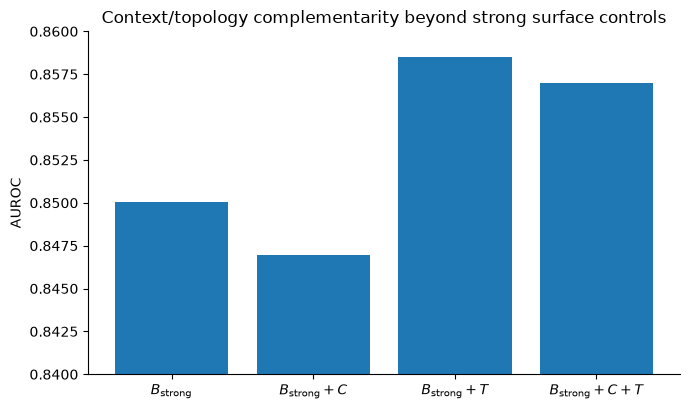

In [13]:
means = split_results.groupby("method")["auroc"].mean()

order = ["Bstrong","Bstrong+C","Bstrong+T","Bstrong+C+T"]

fig, ax = plt.subplots(figsize=(7.0,4.2))
x = np.arange(len(order))
ax.bar(x, [means[m] for m in order])

ax.set_xticks(x)
ax.set_xticklabels([
    r"$B_{\rm strong}$",
    r"$B_{\rm strong}+C$",
    r"$B_{\rm strong}+T$",
    r"$B_{\rm strong}+C+T$",
])
ax.set_ylabel("AUROC")
ax.set_title("Context/topology complementarity beyond strong surface controls")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.ylim(0.84, 0.86)
fig.tight_layout()
fig.savefig(
    FIGURES/"context_topology_strong_baseline.pdf",
    bbox_inches="tight",
)
fig.savefig(
    FIGURES/"context_topology_strong_baseline.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


## Interpretation

The result we want to see is not merely that topology alone predicts generator identity.

The scientifically important comparison is:

\[
\boxed{
(B_{\rm strong}+C+T)-(B_{\rm strong}+C)
}
\]

because it asks whether topology provides source information after controlling for:

1. short-context predictive difficulty;
2. the complete clean context-loss curve;
3. nine transparent lexical/style variables.

If that gain is consistently positive and preferably survives held-out-domain transfer, then context range and dependency topology are genuinely complementary probes under this baseline.

If it disappears here, notebook 10's gain was likely explainable by surface/style information or small-sample variance, and the topology branch should not be scaled further.


In [10]:
def fs(x):
    return f"{x:+.5f}"

print("SOURCE-HELD-OUT")

for a,b in [
    ("Bstrong+C+T","Bstrong+C"),
    ("Bstrong+C+T","Bstrong+T"),
]:
    r = summary[
        (summary["comparison"] == f"{a} vs {b}")
        & (summary["metric"] == "auroc")
    ].iloc[0]

    print(
        f"{a} - {b}",
        "| mean", fs(r.mean_delta),
        "| median", fs(r.median_delta),
        "| IQR", f"[{fs(r.q25)}, {fs(r.q75)}]",
        "| positive", f"{int(r.positive)}/{int(r.n)}",
    )

print("\nHELD-OUT DOMAIN")
sub = transfer_deltas[
    transfer_deltas["comparison"] == "Bstrong+C+T vs Bstrong+C"
]
for r in sub.itertuples(index=False):
    print(
        r.heldout_domain_label,
        "| ΔAUROC", fs(r.delta_auroc),
        "| ΔBalAcc", fs(r.delta_balanced_accuracy),
        "| ΔF1", fs(r.delta_f1),
    )

print("\nREGULARIZATION SWEEP")
display(reg_summary)


SOURCE-HELD-OUT
Bstrong+C+T - Bstrong+C | mean +0.01000 | median +0.01322 | IQR [-0.00057, +0.02110] | positive 14/20
Bstrong+C+T - Bstrong+T | mean -0.00152 | median -0.00115 | IQR [-0.01339, +0.00752] | positive 10/20

HELD-OUT DOMAIN
Essay | ΔAUROC +0.00720 | ΔBalAcc -0.01000 | ΔF1 -0.03494
Reuters | ΔAUROC -0.01184 | ΔBalAcc +0.03000 | ΔF1 +0.02876
Wikipedia | ΔAUROC +0.02458 | ΔBalAcc -0.01136 | ΔF1 -0.00634

REGULARIZATION SWEEP


,C_reg,mean_delta_auroc,median_delta_auroc,q25,q75,positive,n
0,0.01,0.010371,0.009061,-0.000862,0.023631,14,20
1,0.10,0.014646,0.012133,0.007143,0.024353,17,20
2,1.00,0.010000,0.013218,-0.000575,0.021098,14,20
3,10.00,0.000893,-0.000556,-0.003828,0.007553,10,20
